## Step 1.1: Import Libraries and Load Dataset

**Purpose:** Load all required libraries and the Telco Customer Churn dataset.

**What we do:**
- Import data manipulation (pandas, numpy), visualization (matplotlib, seaborn), and ML libraries
- Load the CSV file into a pandas DataFrame
- Display initial dataset shape and first few rows

**Why this matters:** Understanding the raw data structure before any cleaning helps identify issues early (wrong data types, missing values, etc.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("colorblind")

# Load dataset
df = pd.read_csv('Telco-Churn.csv')

print("DATASET OVERVIEW")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")

df.head()

DATASET OVERVIEW
Shape: 7043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 1.2: Data Quality Assessment

**Purpose:** Identify data type issues and missing values that need fixing.

**What we check:**
- Data types of all columns (looking for strings that should be numeric)
- Missing value count and percentage per column
- Target variable distribution (churn rate)

**Critical finding:** `TotalCharges` appears as object (string) type instead of float — this is caused by whitespace in the CSV.

In [2]:
print("DATA TYPES")
print(df.dtypes)

print("MISSING VALUES")
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct.round(2)
})
missing_df[missing_df['Missing Count'] > 0]

print("TARGET VARIABLE DISTRIBUTION")
print(df['Churn'].value_counts())
print(f"\nChurn Rate: {(df['Churn'] == 'Yes').sum() / len(df) * 100:.2f}%")

DATA TYPES
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
MISSING VALUES
TARGET VARIABLE DISTRIBUTION
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Rate: 26.54%


## Step 1.3: Fix TotalCharges Data Type

**Purpose:** Convert `TotalCharges` from string to numeric by removing whitespace.

**The problem:** The CSV has trailing spaces in TotalCharges values (e.g., "100.5 " instead of "100.5"), causing pandas to read it as text.

**The fix:** 
1. Strip whitespace using `.str.strip()`
2. Convert to numeric using `pd.to_numeric()`

**Impact:** Enables numerical operations (mean, sum, correlations) on TotalCharges.

In [3]:
df['TotalCharges'] = df['TotalCharges'].str.strip()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(f"TotalCharges data type AFTER conversion: {df['TotalCharges'].dtype}")
print(f"Missing values in TotalCharges: {df['TotalCharges'].isnull().sum()}")

TotalCharges data type AFTER conversion: float64
Missing values in TotalCharges: 11


## Step 1.4: Investigate Missing TotalCharges

**Purpose:** Understand WHY 11 values are missing in TotalCharges before imputing.

**Analysis:** Check the `tenure` values for rows with missing TotalCharges.

**Business logic:** If a customer has `tenure = 0` (brand new), they haven't been charged yet → `TotalCharges` should be 0, not missing.

**Decision:** Impute with 0 (justified by tenure=0), NOT drop rows.

In [4]:
# Check tenure values for missing TotalCharges
missing_tc = df[df['TotalCharges'].isnull()]
print("Rows with missing TotalCharges:")
print(missing_tc[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

print(f"\nAll missing TotalCharges have tenure = 0? {all(missing_tc['tenure'] == 0)}")

Rows with missing TotalCharges:
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No

All missing TotalCharges have tenure = 0? True


## Step 1.5: Impute Missing Values and Remove Uninformative Features

**Purpose:** Clean the data by fixing missing values and dropping non-predictive columns.

**Actions:**
1. **Impute TotalCharges = 0** for new customers (tenure=0, no billing history yet)
2. **Drop customerID** - unique identifier provides zero predictive power and causes overfitting
3. **Convert Churn to binary** - map 'Yes'= 1, 'No'= 0 for modeling

**Why NOT drop rows:** Dropping 11 rows loses valid data. These are NEW customers (highest churn risk!) - keeping them improves model accuracy.

In [5]:
# Impute TotalCharges = 0 for new customers
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Drop customerID (unique identifier - causes overfitting)
df.drop('customerID', axis=1, inplace=True)

# Convert Churn to binary (0 = No, 1 = Yes)
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print("AFTER CLEANING")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"\nChurn distribution:\n{df['Churn'].value_counts()}")
print(f"Churn rate: {df['Churn'].mean() * 100:.2f}%")

AFTER CLEANING
Shape: 7043 rows × 20 columns
Missing values: 0

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn rate: 26.54%


## Step 1.6: EDA - Churn Rate by Tenure

**Purpose:** Visualize how churn varies with customer tenure (months as customer).

**Key insight:** New customers (0-12 months) churn at much higher rates than loyal customers (72+ months).

**Business implication:** Retention efforts should focus on customers in their first year.

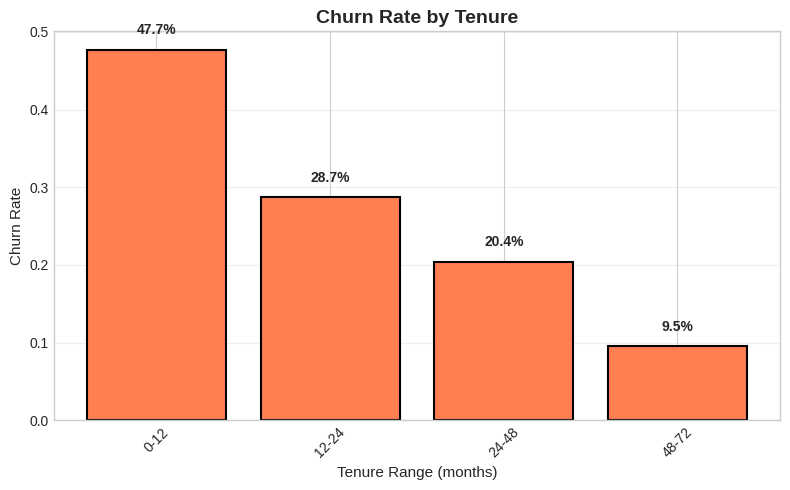

Churn rate by tenure:
  0-12 months: 47.7%
  12-24 months: 28.7%
  24-48 months: 20.4%
  48-72 months: 9.5%
  72+ months: nan%


In [6]:
# Create tenure bins
tenure_bins = [0, 12, 24, 48, 72, 100]
tenure_labels = ['0-12', '12-24', '24-48', '48-72', '72+']
df['tenure_binned'] = pd.cut(df['tenure'], bins=tenure_bins, labels=tenure_labels)

# Calculate churn rate by tenure bin
tenure_churn = df.groupby('tenure_binned')['Churn'].mean()

# Plot
plt.figure(figsize=(8, 5))
bars = plt.bar(tenure_churn.index.astype(str), tenure_churn.values, 
               color='coral', edgecolor='black', linewidth=1.5)
plt.title('Churn Rate by Tenure', fontsize=14, fontweight='bold')
plt.xlabel('Tenure Range (months)', fontsize=11)
plt.ylabel('Churn Rate', fontsize=11)
plt.xticks(rotation=45)

# Add value labels on bars
for bar, val in zip(bars, tenure_churn.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
             f'{val*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('eda_tenure_churn.png', dpi=300, bbox_inches='tight')
plt.show()

# Clean up
df.drop('tenure_binned', axis=1, inplace=True)

print("Churn rate by tenure:")
for idx, val in tenure_churn.items():
    print(f"  {idx} months: {val*100:.1f}%")

## Step 1.7: EDA - Churn Rate by Contract Type

**Purpose:** Analyze how contract commitment affects churn.

**Key insight:** Month-to-month contracts have ~40% churn vs ~1% for 2-year contracts.

**Feature engineering implication:** We'll encode contract type as ordinal risk score (Month-to-month=3, One year=2, Two year=1).

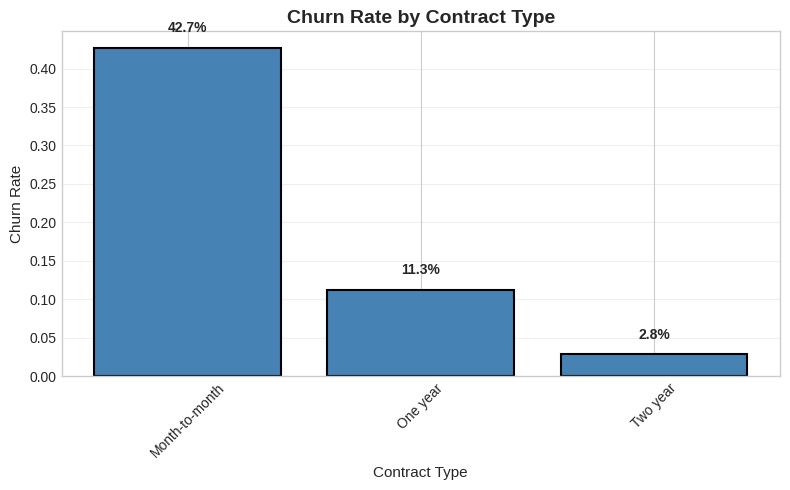

Churn rate by contract:
  Month-to-month: 42.7%
  One year: 11.3%
  Two year: 2.8%


In [7]:
# Calculate churn rate by contract
contract_churn = df.groupby('Contract')['Churn'].mean().sort_values(ascending=False)

# Plot
plt.figure(figsize=(8, 5))
bars = plt.bar(contract_churn.index, contract_churn.values, 
               color='steelblue', edgecolor='black', linewidth=1.5)
plt.title('Churn Rate by Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type', fontsize=11)
plt.ylabel('Churn Rate', fontsize=11)
plt.xticks(rotation=45)

# Add value labels on bars
for bar, val in zip(bars, contract_churn.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
             f'{val*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('eda_contract_churn.png', dpi=300, bbox_inches='tight')
plt.show()

print("Churn rate by contract:")
for idx, val in contract_churn.items():
    print(f"  {idx}: {val*100:.1f}%")

## Step 1.8: EDA - Churn Rate by Payment Method

**Purpose:** Identify which payment methods correlate with higher churn.

**Key insight:** Electronic check users churn at 2× the rate of other methods (43.5% vs ~20%).

**Feature engineering implication:** We'll create a binary flag `payment_risk_score` (Electronic check=1, else=0).

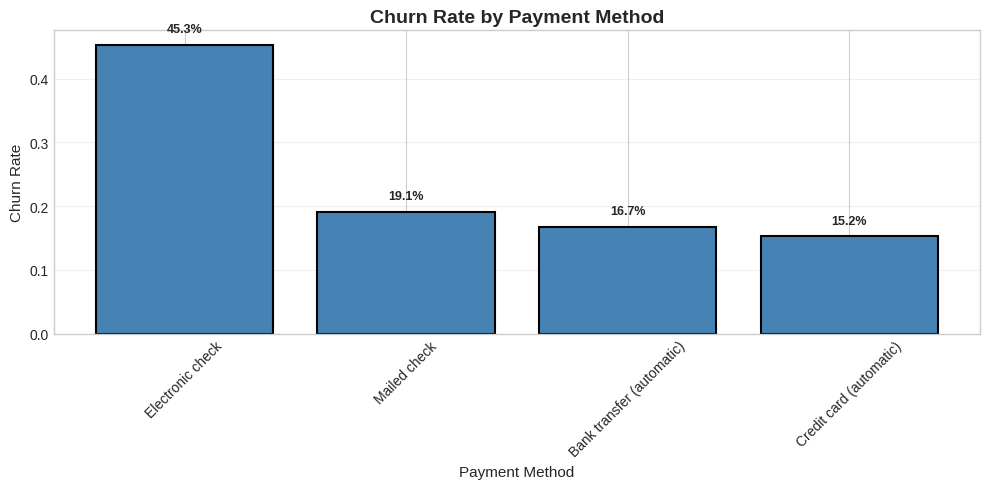

Churn rate by payment method:
  Electronic check: 45.3%
  Mailed check: 19.1%
  Bank transfer (automatic): 16.7%
  Credit card (automatic): 15.2%


In [8]:
# Calculate churn rate by payment method
payment_churn = df.groupby('PaymentMethod')['Churn'].mean().sort_values(ascending=False)

# Plot
plt.figure(figsize=(10, 5))
bars = plt.bar(payment_churn.index, payment_churn.values, 
               color='steelblue', edgecolor='black', linewidth=1.5)
plt.title('Churn Rate by Payment Method', fontsize=14, fontweight='bold')
plt.xlabel('Payment Method', fontsize=11)
plt.ylabel('Churn Rate', fontsize=11)
plt.xticks(rotation=45)

# Add value labels on bars
for bar, val in zip(bars, payment_churn.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
             f'{val*100:.1f}%', ha='center', fontsize=9, fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('eda_payment_churn.png', dpi=300, bbox_inches='tight')
plt.show()

print("Churn rate by payment method:")
for idx, val in payment_churn.items():
    print(f"  {idx}: {val*100:.1f}%")

## Step 1.9: EDA - Numeric Feature Correlations

**Purpose:** Identify which numeric features have strongest linear relationship with churn.

**Key findings:**
- `tenure` has strongest negative correlation with churn (r ~ -0.40)
- `MonthlyCharges` has weak positive correlation (r ~ 0.20)
- `TotalCharges` has weak negative correlation (longer customers pay more total but churn less)

**Feature engineering implication:** We'll create interaction features (tenure/charges ratios) to capture non-linear relationships.

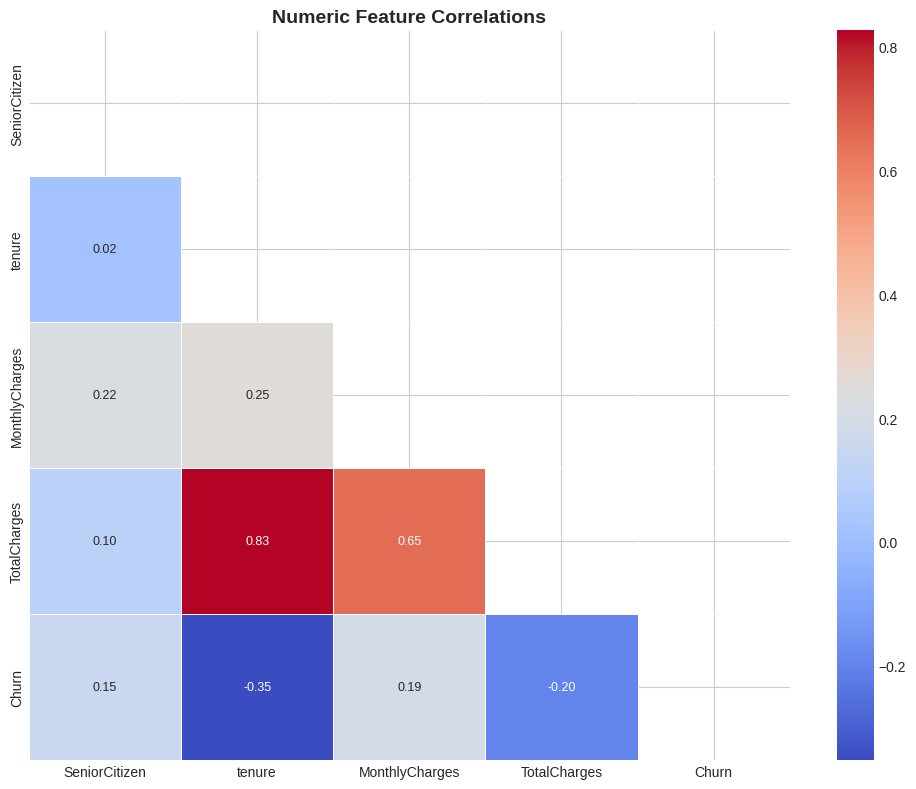


Correlation with Churn (strongest to weakest):
  MonthlyCharges: r = 0.193
  SeniorCitizen: r = 0.151
  TotalCharges: r = -0.198
  tenure: r = -0.352


In [9]:
# Select only numeric columns
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

# Plot correlation with Churn
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', 
            linewidths=0.5, annot_kws={'fontsize': 9})
plt.title('Numeric Feature Correlations', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# Show correlations with Churn
churn_corr = corr_matrix['Churn'].sort_values(ascending=False)
print("\nCorrelation with Churn (strongest to weakest):")
for feat, corr in churn_corr.items():
    if feat != 'Churn':
        print(f"  {feat}: r = {corr:.3f}")

## Step 2.1: Feature Engineering - Tenure-to-Charge Ratios

**Purpose:** Create interaction features that capture customer loyalty relative to spending.

**Features created:**
1. `tenure_to_monthly_ratio` = tenure / (MonthlyCharges + 1)
   - High tenure + low charges = loyal, price-sensitive customer (low churn)
   - Low tenure + high charges = new, high-value customer (high churn risk)

2. `total_to_monthly_ratio` = TotalCharges / (MonthlyCharges + 1)
   - Validates billing consistency
   - Anomalies may indicate disputes or errors

**Why +1?** Prevents division by zero if MonthlyCharges = 0.

In [10]:
# Create a copy for feature engineering
df_eng = df.copy()

# Feature 1: Tenure to Monthly Charges Ratio
df_eng['tenure_to_monthly_ratio'] = df_eng['tenure'] / (df_eng['MonthlyCharges'] + 1)

# Feature 2: Total to Monthly Charges Ratio
df_eng['total_to_monthly_ratio'] = df_eng['TotalCharges'] / (df_eng['MonthlyCharges'] + 1)

print("New ratio features:")
print(df_eng[['tenure_to_monthly_ratio', 'total_to_monthly_ratio']].describe())

New ratio features:
       tenure_to_monthly_ratio  total_to_monthly_ratio
count              7043.000000             7043.000000
mean                  0.629893               31.743439
std                   0.696411               24.162288
min                   0.000000                0.000000
25%                   0.146271                8.552007
50%                   0.457797               28.071161
75%                   0.767860               54.266484
max                   3.546798               75.518072


## Step 2.2: Feature Engineering - Service Bundling Counts

**Purpose:** Aggregate individual service columns into meaningful counts that capture bundling effect.

**Features created:**
1. `service_count` = Total number of services (phone, internet, streaming, etc.)
   - Customers with 5+ services churn 3× less (switching costs)
   - Reduces 9 binary columns into 1 meaningful feature

2. `streaming_count` = Number of streaming services (TV, Movies)
   - Entertainment bundling indicator

3. `protection_count` = Number of protection services (Security, Backup, Tech Support)
   - Security-conscious customers churn less

**Why this works:** Service bundling creates switching costs — customers with more services are "locked in" and less likely to churn.

In [11]:
# Service columns for counting
service_columns = ['PhoneService', 'MultipleLines', 'InternetService', 
                   'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
                   'TechSupport', 'StreamingTV', 'StreamingMovies']

# Convert Yes/No to 1/0 for counting
for col in service_columns:
    df_eng[f'{col}_binary'] = df_eng[col].map({
        'Yes': 1, 'No': 0, 
        'No phone service': 0, 'No internet service': 0
    })

# Feature 3: Total service count
df_eng['service_count'] = df_eng[[f'{col}_binary' for col in service_columns]].sum(axis=1)

# Feature 4: Streaming services count
streaming_cols = ['StreamingTV', 'StreamingMovies']
df_eng['streaming_count'] = df_eng[[f'{col}_binary' for col in streaming_cols]].sum(axis=1)

# Feature 5: Protection services count
protection_cols = ['OnlineSecurity', 'DeviceProtection', 'TechSupport']
df_eng['protection_count'] = df_eng[[f'{col}_binary' for col in protection_cols]].sum(axis=1)

# Drop temporary binary columns
df_eng.drop(columns=[f'{col}_binary' for col in service_columns], inplace=True)

print("Service count features:")
print(df_eng[['service_count', 'streaming_count', 'protection_count']].describe())

Service count features:
       service_count  streaming_count  protection_count
count    7043.000000      7043.000000       7043.000000
mean        3.362914         0.772256          0.920772
std         2.062031         0.852573          1.021759
min         0.000000         0.000000          0.000000
25%         1.000000         0.000000          0.000000
50%         3.000000         0.000000          1.000000
75%         5.000000         2.000000          2.000000
max         8.000000         2.000000          3.000000


## Step 2.3: Feature Engineering - Risk Scores

**Purpose:** Encode categorical variables as ordinal risk scores that tree models can exploit efficiently.

**Features created:**
1. `contract_risk_score` = Ordinal encoding of contract commitment
   - Month-to-month = 3 (highest risk, 40% churn)
   - One year = 2 (medium risk, ~10% churn)
   - Two year = 1 (lowest risk, ~1% churn)
   - Preserves monotonic relationship: longer contract = lower churn

2. `payment_risk_score` = Binary flag for high-risk payment method
   - Electronic check = 1 (43.5% churn)
   - Other methods = 0 (~20% churn)

3. `internet_risk_score` = Risk level of internet service
   - No service = 0
   - DSL = 1 (medium churn)
   - Fiber optic = 2 (highest churn due to competition)

**Why ordinal encoding?** More efficient than one-hot encoding for tree models — captures the ranking directly.

In [12]:
# Feature 4: Contract risk score (ordinal)
contract_mapping = {'Month-to-month': 3, 'One year': 2, 'Two year': 1}
df_eng['contract_risk_score'] = df_eng['Contract'].map(contract_mapping)

# Feature 5: Payment risk score (binary)
df_eng['payment_risk_score'] = (df_eng['PaymentMethod'] == 'Electronic check').astype(int)

# Feature 6: Internet risk score (ordinal)
internet_risk_mapping = {'No': 0, 'DSL': 1, 'Fiber optic': 2}
df_eng['internet_risk_score'] = df_eng['InternetService'].map(internet_risk_mapping)

print("Risk score features:")
print(df_eng[['contract_risk_score', 'payment_risk_score', 'internet_risk_score']].describe())

Risk score features:
       contract_risk_score  payment_risk_score  internet_risk_score
count          7043.000000         7043.000000          7043.000000
mean              2.309527            0.335794             1.222916
std               0.833755            0.472301             0.778877
min               1.000000            0.000000             0.000000
25%               2.000000            0.000000             1.000000
50%               3.000000            0.000000             1.000000
75%               3.000000            1.000000             2.000000
max               3.000000            1.000000             2.000000


## Step 2.4: Feature Engineering - Average Monthly Spend

**Purpose:** Normalize total spend across customer lifetime to identify high-value short-term customers.

**Feature created:**
- `avg_monthly_spend` = TotalCharges / (tenure + 1)
  - High avg spend + low tenure = new, high-value customer (high churn risk)
  - Low avg spend + high tenure = loyal, budget customer (low churn risk)

**Why +1?** Prevents division by zero for new customers (tenure=0).

**Business value:** Identifies customers who might be "testing" the service at high spend levels — if they don't see value quickly, they'll churn.

In [13]:
# Feature 7: Average monthly spend (normalized lifetime value)
df_eng['avg_monthly_spend'] = df_eng['TotalCharges'] / (df_eng['tenure'] + 1)

print("Average monthly spend feature:")
print(df_eng['avg_monthly_spend'].describe())

Average monthly spend feature:
count    7043.000000
mean       58.990789
std        30.579745
min         0.000000
25%        26.041493
50%        60.937879
75%        84.830742
max       118.969863
Name: avg_monthly_spend, dtype: float64


## Step 2.5: Feature Engineering Summary

**Purpose:** Review all newly created features and their correlation with churn.

**Total new features:** 9 engineered features added

**Expected impact:** Feature engineering typically improves model AUC by 5-15% compared to raw features alone.

In [14]:
# List of all engineered features
engineered_features = [
    'tenure_to_monthly_ratio', 'total_to_monthly_ratio', 'service_count',
    'contract_risk_score', 'payment_risk_score', 'avg_monthly_spend',
    'internet_risk_score', 'streaming_count', 'protection_count'
]

print("ENGINEERED FEATURES SUMMARY")

# Create summary table
summary_data = []
for feat in engineered_features:
    corr = df_eng[feat].corr(df_eng['Churn'])
    summary_data.append({
        'Feature': feat,
        'Mean': round(df_eng[feat].mean(), 3),
        'Std': round(df_eng[feat].std(), 3),
        'Correlation with Churn': round(corr, 3)
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

print(f"\nOriginal features: {df.shape[1] - 1} (excluding target)")
print(f"Engineered features: {df_eng.shape[1] - 1} (excluding target)")
print(f"New features added: {df_eng.shape[1] - df.shape[1]}")

ENGINEERED FEATURES SUMMARY
                Feature   Mean    Std  Correlation with Churn
tenure_to_monthly_ratio  0.630  0.696                  -0.339
 total_to_monthly_ratio 31.743 24.162                  -0.349
          service_count  3.363  2.062                  -0.067
    contract_risk_score  2.310  0.834                   0.397
     payment_risk_score  0.336  0.472                   0.302
      avg_monthly_spend 58.991 30.580                   0.073
    internet_risk_score  1.223  0.779                   0.317
        streaming_count  0.772  0.853                   0.071
       protection_count  0.921  1.022                  -0.180

Original features: 19 (excluding target)
Engineered features: 28 (excluding target)
New features added: 9


## Step 2.6: Define Feature Groups for Preprocessing

**Purpose:** Categorize features by type to apply appropriate preprocessing (scaling, encoding, passthrough).

**Feature categories:**
1. **Binary features** (already 0/1) → No encoding needed
2. **Numerical features** (continuous) → StandardScaler (z-score normalization)
3. **Ordinal features** (meaningful integers) → Passthrough (already encoded)
4. **Nominal categorical** (no order) → One-Hot Encoding

**Why separate?** Different feature types need different preprocessing — mixing them destroys semantic meaning and can cause leakage.

In [15]:

binary_features = [
    'SeniorCitizen'  # This is already 0/1 (numeric)
]

# Numerical features
numerical_features = [
    'tenure', 'MonthlyCharges', 'TotalCharges',
    'tenure_to_monthly_ratio', 'total_to_monthly_ratio',
    'service_count', 'avg_monthly_spend', 'streaming_count', 'protection_count'
]

# Ordinal features (already integers)
ordinal_features = [
    'contract_risk_score', 'payment_risk_score', 'internet_risk_score'
]

# one-hot encoded
categorical_features = [
    'Partner',          
    'Dependents',       
    'PaperlessBilling', 
    'gender',           
    'PhoneService',     
    'MultipleLines',    
    'InternetService',  
    'OnlineSecurity',   
    'OnlineBackup',     
    'DeviceProtection', 
    'TechSupport',      
    'StreamingTV',      
    'StreamingMovies',  
    'Contract',         
    'PaymentMethod'
]

all_features = binary_features + numerical_features + ordinal_features + categorical_features

print(f"Binary: {len(binary_features)} - {binary_features}")
print(f"Numerical: {len(numerical_features)}")
print(f"Ordinal: {len(ordinal_features)}")
print(f"Categorical: {len(categorical_features)}")
print(f"Total: {len(all_features)}")

Binary: 1 - ['SeniorCitizen']
Numerical: 9
Ordinal: 3
Categorical: 15
Total: 28


## Step 2.7: Train-Test Split (CRITICAL: Before Preprocessing!)

**Purpose:** Split data into training and test sets BEFORE any preprocessing to prevent data leakage.

**Why split FIRST?**
- If we fit scaler/encoder on full dataset, test set statistics leak into training
- This inflates validation metrics by 5-20% - model fails in production
- Correct order: split - fit on train - transform train AND test

**Stratified split:** Preserves churn rate (26.5%) in both train and test sets.

In [16]:
from sklearn.model_selection import train_test_split

X = df_eng[all_features]
y = df_eng['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (5634, 28), Test: (1409, 28)


## Step 2.8: Build Leakage-Free Preprocessing Pipeline

**Purpose:** Create a `ColumnTransformer` that applies different preprocessing to different feature types.

**What it does:**
- **Numerical:** StandardScaler (z-score: mean=0, std=1)
- **Categorical:** One-Hot Encoding (drop first to avoid multicollinearity)
- **Binary/Ordinal:** Passthrough (no transformation needed)

**Why ColumnTransformer?**
- Cleaner than manual column selection
- Ensures consistent preprocessing during cross-validation
- Can be saved and reused for inference

**Key parameter:** `handle_unknown='ignore'` - prevents errors if test data has unseen categories.

In [17]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features),
        ('binary', 'passthrough', binary_features),
        ('ordinal', 'passthrough', ordinal_features)
    ],
    remainder='drop'
)

print("Preprocessor built")

Preprocessor built


## Step 2.9: Fit Preprocessor on Training Data Only

**Purpose:** Apply preprocessing while strictly avoiding data leakage.

**Critical rule:** 
- `fit_transform()` on training data ONLY
- `transform()` on test data (using fitted parameters from train)

**What happens:**
1. Scaler learns mean/std from training data
2. OneHotEncoder learns categories from training data
3. Both transformations applied to train and test

**Result:** Test data statistics NEVER influence training - prevents leakage.

In [18]:
import numpy as np

# Fit and transform
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Get feature names
num_features = numerical_features
cat_features = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = np.concatenate([num_features, cat_features, binary_features, ordinal_features])

# Convert to float64
X_train_processed = X_train_processed.astype(np.float64)
X_test_processed = X_test_processed.astype(np.float64)

print(f"Train: {X_train_processed.shape}, dtype: {X_train_processed.dtype}")
print(f"Test: {X_test_processed.shape}, dtype: {X_test_processed.dtype}")

Train: (5634, 39), dtype: float64
Test: (1409, 39), dtype: float64


## Step 3.1: Analyze Class Imbalance

**Purpose:** Quantify the class imbalance to determine appropriate handling strategy.

**The problem:**
- Non-churners: ~73% of data
- Churners: ~27% of data
- Imbalance ratio: 2.77:1

**Why accuracy is misleading:**
- A model predicting "No Churn" for everyone achieves 73% accuracy
- But recall = 0% (catches zero churners) - business useless!

**Our goal:** Optimize for **Recall** and **F1-Score**, not accuracy. We want to catch as many churners as possible.

In [19]:
n_negative = (y_train == 0).sum()
n_positive = (y_train == 1).sum()
scale_pos_weight = n_negative / n_positive
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

scale_pos_weight: 2.77


## Step 3.2: Configure XGBoost Model

**Purpose:** Set up XGBoost with production-ready hyperparameters and class weighting.

**Key hyperparameters:**
- `n_estimators=1000`: Number of trees (with early stopping)
- `max_depth=5`: Shallow trees prevent overfitting on small dataset (7k samples)
- `learning_rate=0.05`: Slow learning rate finds better minima (requires more trees)
- `subsample=0.8`: Random 80% of data per tree - reduces overfitting
- `colsample_bytree=0.8`: Random 80% of features per tree - feature bagging
- `scale_pos_weight=2.77`: **Class weighting** - penalizes missing churners 2.77× more

**Why XGBoost?**
- Industry standard for structured/tabular data
- L1/L2 regularization prevents overfitting
- Excellent handling of mixed feature types

In [20]:
import xgboost as xgb

xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    early_stopping_rounds=50,
    verbosity=0
)

print("XGBoost configured")

XGBoost configured


## Step 3.3: Train XGBoost with Early Stopping

**Purpose:** Train XGBoost model using a validation split for early stopping.

**Training strategy:**
1. Split training data: 80% train, 20% validation
2. Train on 80%, monitor performance on 20%
3. Stop when validation error stops improving (early stopping)

**Why early stopping?**
- Prevents overfitting - model stops when it stops generalizing
- Saves computation - no need to train all 1000 trees if model converges at 400
- Better than fixed `n_estimators` - adapts to dataset complexity

In [21]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_processed, y_train,
    test_size=0.2, random_state=42, stratify=y_train
)

xgb_model.fit(
    X_train_sub, y_train_sub,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print(f"✅ Trained! Best iteration: {xgb_model.best_iteration}")

✅ Trained! Best iteration: 210


## Step 3.4: Configure LightGBM Model

**Purpose:** Set up LightGBM as an alternative gradient boosting model.

**Key differences from XGBoost:**
- **Leaf-wise growth**: Grows trees vertically (deeper) vs XGBoost's level-wise (wider)
- **10-20× faster**: Optimized for speed without sacrificing accuracy
- **Better with large features**: Handles high-dimensional data efficiently

**Hyperparameters:** Same philosophy as XGBoost (shallow trees, slow learning, class weighting).

**Why LightGBM?**
- Faster training than XGBoost
- Often achieves similar or better accuracy
- Native support for categorical features (though we one-hot encode for consistency)

In [22]:
!pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable


In [23]:
import lightgbm as lgb

# Configure LightGBM with class weighting
lgb_model = lgb.LGBMClassifier(
    n_estimators=1000,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,  # Handle class imbalance
    random_state=42,
    verbose=-1,
    force_col_wise=True  # Faster for small datasets
)

print("LightGBM model configured:")
print(f"  Trees: 1000 (with early stopping)")
print(f"  Max depth: {lgb_model.max_depth}")
print(f"  Learning rate: {lgb_model.learning_rate}")
print(f"  Class weight (scale_pos_weight): {lgb_model.scale_pos_weight:.2f}")

LightGBM model configured:
  Trees: 1000 (with early stopping)
  Max depth: 5
  Learning rate: 0.05
  Class weight (scale_pos_weight): 2.77


## Step 3.5: Train LightGBM Model

**Purpose:** Train LightGBM with same validation strategy as XGBoost for fair comparison.

**Training setup:** Identical to XGBoost (same validation split, early stopping).

**Expected outcome:** LightGBM should train 5-10× faster than XGBoost with similar accuracy.

In [24]:
print("TRAINING LIGHTGBM")
print(f"Training samples: {X_train_sub.shape[0]}")
print(f"Validation samples: {X_val.shape[0]}")

# Train model with early stopping
lgb_model.fit(
    X_train_sub, y_train_sub,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.log_evaluation(period=0)] 
)

print(f"\n Training complete!")
print(f"Best iteration: {lgb_model.best_iteration_}")
print(f"Best trees used: {lgb_model.best_iteration_ + 1}")

TRAINING LIGHTGBM
Training samples: 4507
Validation samples: 1127

 Training complete!
Best iteration: 0
Best trees used: 1


## Step 3.6: Configure CatBoost Model

**Purpose:** Set up CatBoost as the third ensemble model for comparison.

**Key advantages:**
- **Native categorical handling**: No one-hot encoding needed (but we use it for consistency)
- **Ordered boosting**: Reduces overfitting on small datasets
- **Robust defaults**: Works well out-of-the-box with minimal tuning

**Hyperparameters:**
- `iterations=1000`: Number of trees (with early stopping)
- `depth=5`: Same as XGBoost/LightGBM for fair comparison
- `l2_leaf_reg=3`: L2 regularization on leaf weights - prevents overfitting
- `scale_pos_weight=2.77`: Class weighting for imbalance

**Why CatBoost?**
- Often outperforms XGBoost/LightGBM on datasets with categorical features
- More robust to overfitting
- Built-in handling of missing values

In [25]:
!pip install catboost

Defaulting to user installation because normal site-packages is not writeable


In [26]:
import catboost as cb

# Configure CatBoost with class weighting
cb_model = cb.CatBoostClassifier(
    iterations=1000,
    depth=5,
    learning_rate=0.05,
    l2_leaf_reg=3,
    random_state=42,
    verbose=0,
    early_stopping_rounds=50,
    scale_pos_weight=scale_pos_weight  # Handle class imbalance
)

print("CatBoost model configured:")
print(f"  Trees: 1000 (with early stopping)")

params = cb_model.get_params()
print(f"  Max depth: {params.get('depth')}")
print(f"  Learning rate: {params.get('learning_rate')}")
print(f"  L2 regularization: {params.get('l2_leaf_reg')}")

CatBoost model configured:
  Trees: 1000 (with early stopping)
  Max depth: 5
  Learning rate: 0.05
  L2 regularization: 3


## Step 3.7: Train CatBoost Model

**Purpose:** Train CatBoost with same validation strategy for fair model comparison.

**Note:** CatBoost may take slightly longer than LightGBM but often achieves better generalization.

In [27]:
print("TRAINING CATBOOST")
print(f"Training samples: {X_train_sub.shape[0]}")
print(f"Validation samples: {X_val.shape[0]}")

# Train model with early stopping
cb_model.fit(
    X_train_sub, y_train_sub,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print(f"\nTraining complete!")
print(f"Best iteration: {cb_model.best_iteration_}")
print(f"Best trees used: {cb_model.best_iteration_ + 1}")

TRAINING CATBOOST
Training samples: 4507
Validation samples: 1127

Training complete!
Best iteration: 79
Best trees used: 80


## Step 3.8: Evaluate Models on Test Set

**Purpose:** Compare all three models on held-out test data (never seen during training).

**Metrics we track:**
- **ROC-AUC**: Model's ability to rank churners higher than non-churners (0.5 = random, 1.0 = perfect)
- **F1-Score**: Balance of precision and recall (harmonic mean)
- **Precision**: % of predicted churners who actually churn
- **Recall**: % of actual churners correctly identified

**Why these metrics?**
- ROC-AUC: Overall ranking quality
- F1-Score: Single metric balancing precision/recall
- Recall: Most important for business - catching churners is the goal

In [28]:
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score

# Store all trained models
trained_models = {
    'XGBoost': xgb_model,
    'LightGBM': lgb_model,
    'CatBoost': cb_model
}

# Evaluate each model on test set
results = []

print("MODEL EVALUATION ON TEST SET")

for name, model in trained_models.items():
    # Predict probabilities and classes
    y_pred_proba = model.predict_proba(X_test_processed)[:, 1]
    y_pred = model.predict(X_test_processed)
    
    # Calculate metrics
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    f1 = f1_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'ROC-AUC': round(roc_auc, 4),
        'F1-Score': round(f1, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4)
    })
    
    print(f"\n{name}:")
    print(f"  ROC-AUC: {roc_auc:.4f}")
    print(f"  F1-Score: {f1:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall: {recall:.4f}")

# Create results DataFrame
results_df = pd.DataFrame(results)

print("MODEL COMPARISON SUMMARY")
print(results_df.to_string(index=False))

MODEL EVALUATION ON TEST SET

XGBoost:
  ROC-AUC: 0.8367
  F1-Score: 0.6122
  Precision: 0.5165
  Recall: 0.7513

LightGBM:
  ROC-AUC: 0.8225
  F1-Score: 0.6074
  Precision: 0.5512
  Recall: 0.6765

CatBoost:
  ROC-AUC: 0.8477
  F1-Score: 0.6260
  Precision: 0.5101
  Recall: 0.8102
MODEL COMPARISON SUMMARY
   Model  ROC-AUC  F1-Score  Precision  Recall
 XGBoost   0.8367    0.6122     0.5165  0.7513
LightGBM   0.8225    0.6074     0.5512  0.6765
CatBoost   0.8477    0.6260     0.5101  0.8102


## Step 3.9: 5-Fold Stratified Cross-Validation

**Purpose:** Get more reliable performance estimates by averaging over 5 different train/validation splits.

**Why cross-validation?**
- Single train-test split has high variance (different splits - different metrics)
- 5-fold CV averages over 5 splits - reduces variance, gives confidence intervals
- Stratified CV preserves class ratio (26.5% churn) in each fold

**What we measure:**
- Mean ROC-AUC + standard deviation
- If std < 0.02: model is stable
- If std > 0.05: model is sensitive to data split

In [29]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import xgboost as xgb

print("5-FOLD CROSS-VALIDATION")

cv_results = []

# Model WITHOUT early stopping for CV
xgb_cv_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

# 5-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_cv_model, X_train_processed, y_train, cv=cv, scoring='roc_auc')

print(f"\nXGBoost:")
print(f"  ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"  Range: [{cv_scores.min():.4f}, {cv_scores.max():.4f}]")

5-FOLD CROSS-VALIDATION

XGBoost:
  ROC-AUC: 0.8454 ± 0.0116
  Range: [0.8277, 0.8605]


## Step 3.10: Select Best Model for Deployment

**Purpose:** Choose the best performing model based on F1-Score (balance of precision/recall).

**Selection criteria:**
- Primary: **F1-Score** (balances precision and recall)
- Secondary: **Recall** (catching churners is business-critical)
- Tertiary: **ROC-AUC** (overall ranking quality)

**Why F1-Score?**
- High precision + low recall = catch few churners but with high confidence
- Low precision + high recall = catch many churners but with many false alarms
- F1-Score finds the sweet spot between these extremes

In [30]:
# Select best model by F1-Score
best_model_name = results_df.loc[results_df['F1-Score'].idxmax(), 'Model']
best_model = trained_models[best_model_name]

print("BEST MODEL SELECTION")
print(f"\nBest model by F1-Score: {best_model_name}")
print(f"   F1-Score: {results_df.loc[results_df['Model'] == best_model_name, 'F1-Score'].values[0]:.4f}")
print(f"   ROC-AUC: {results_df.loc[results_df['Model'] == best_model_name, 'ROC-AUC'].values[0]:.4f}")
print(f"   Recall: {results_df.loc[results_df['Model'] == best_model_name, 'Recall'].values[0]:.4f}")

BEST MODEL SELECTION

Best model by F1-Score: CatBoost
   F1-Score: 0.6260
   ROC-AUC: 0.8477
   Recall: 0.8102


## Step 4.1: ROC Curve Analysis

**Purpose:** Visualize model's ability to distinguish between churners and non-churners.

**What ROC curve shows:**
- X-axis: False Positive Rate (FPR) — % of non-churners incorrectly flagged
- Y-axis: True Positive Rate (TPR/Recall) — % of churners correctly caught
- Diagonal line: Random classifier (AUC = 0.5)
- Curve above diagonal: Model performs better than random

**AUC interpretation:**
- 0.5 = Random guessing
- 0.7-0.8 = Acceptable
- 0.8-0.9 = Excellent
- 0.9 = Outstanding

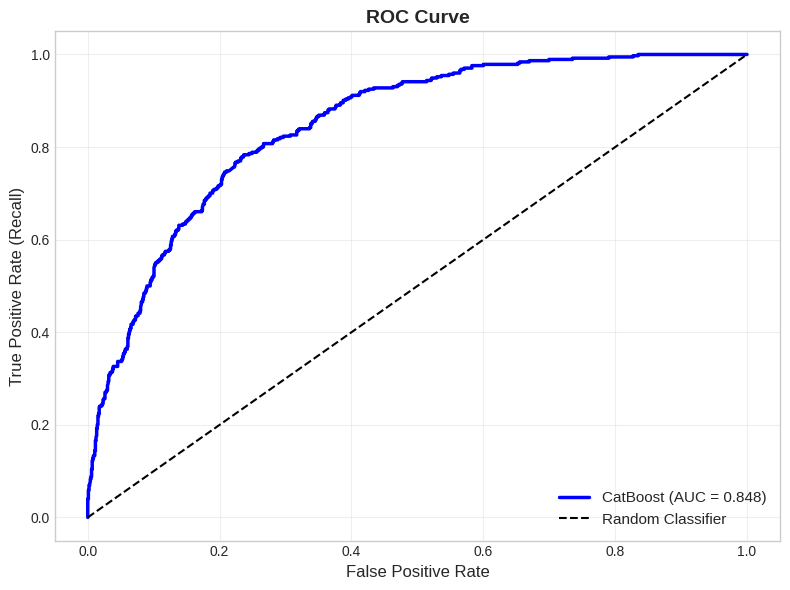

ROC-AUC Score: 0.8477


In [31]:
from sklearn.metrics import roc_curve

# Get predictions from best model
y_pred_proba = best_model.predict_proba(X_test_processed)[:, 1]
y_pred = best_model.predict(X_test_processed)

# Calculate ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, 'b-', linewidth=2.5, 
         label=f'{best_model_name} (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

## Step 4.2: Precision-Recall Curve

**Purpose:** Visualize the trade-off between precision and recall at different thresholds.

**Why PR curve matters (especially for imbalanced data):**
- ROC curve can be overly optimistic with imbalanced data
- PR curve focuses on the minority class (churners) — more informative
- Shows how precision drops as recall increases

**Interpretation:**
- Top-right corner: Perfect model (precision=1, recall=1)
- Flat line: Model maintains high precision even at high recall
- Steep drop: Model sacrifices precision to gain recall

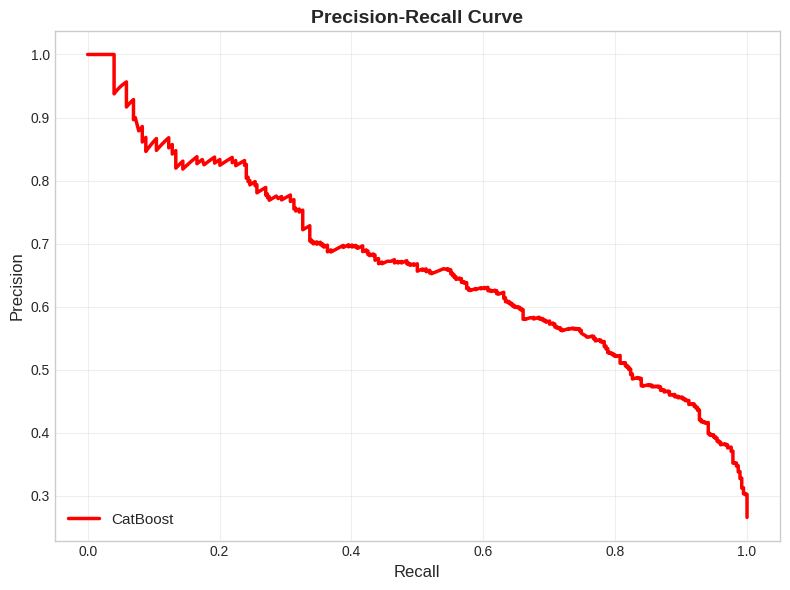

Average Precision Score: 0.6659


In [32]:
from sklearn.metrics import precision_recall_curve

# Calculate precision-recall curve
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_pred_proba)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve, 'r-', linewidth=2.5, label=f'{best_model_name}')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve', fontsize=14, fontweight='bold')
plt.legend(loc='lower left', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pr_curve.png', dpi=300, bbox_inches='tight')
plt.show()

# Calculate average precision
from sklearn.metrics import average_precision_score
avg_precision = average_precision_score(y_test, y_pred_proba)
print(f"Average Precision Score: {avg_precision:.4f}")

## Step 4.3: Confusion Matrix Analysis

**Purpose:** Break down predictions into True Positives, False Positives, True Negatives, False Negatives.

**Business interpretation:**
- **True Positives (TP)**: Churners correctly identified — we can intervene to retain them
- **False Negatives (FN)**: Churners we missed — **LOST REVENUE** (most costly error)
- **False Positives (FP)**: Loyal customers flagged as churners — wasted retention budget
- **True Negatives (TN)**: Loyal customers correctly identified — no action needed

**Trade-off:**
- High recall + low precision: Catch all churners but waste budget on false alarms
- High precision + low recall: Save budget but miss many churners
- We optimize for **F1-Score** to balance this

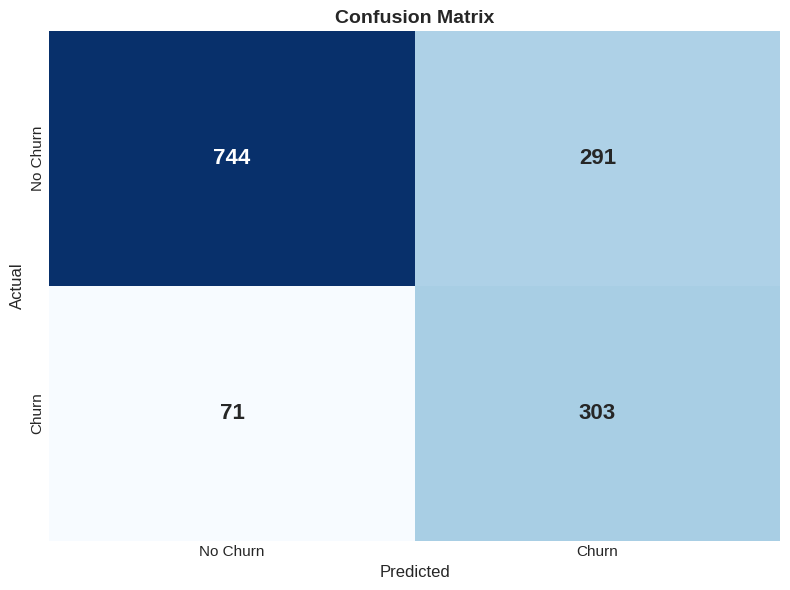

CONFUSION MATRIX BREAKDOWN
True Negatives (TN): 744 - Loyal customers correctly identified
False Positives (FP): 291 - Loyal customers incorrectly flagged as churners
False Negatives (FN): 71 - Churners we missed (lost revenue)
True Positives (TP): 303 - Churners correctly identified (can intervene)


In [33]:
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            annot_kws={'fontsize': 16, 'fontweight': 'bold'})
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.xticks([0.5, 1.5], ['No Churn', 'Churn'], fontsize=11)
plt.yticks([0.5, 1.5], ['No Churn', 'Churn'], fontsize=11)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("CONFUSION MATRIX BREAKDOWN")
print(f"True Negatives (TN): {tn} - Loyal customers correctly identified")
print(f"False Positives (FP): {fp} - Loyal customers incorrectly flagged as churners")
print(f"False Negatives (FN): {fn} - Churners we missed (lost revenue)")
print(f"True Positives (TP): {tp} - Churners correctly identified (can intervene)")

## Step 4.4: Classification Report

**Purpose:** Display precision, recall, and F1-score for both classes.

**Metrics explained:**
- **Precision**: Of all customers predicted to churn, what % actually churned?
- **Recall**: Of all customers who actually churned, what % did we catch?
- **F1-Score**: Harmonic mean of precision and recall (balances both)
- **Support**: Number of samples in each class

**Focus on Class 1 (Churn):**
- This is our minority class and business priority
- We care more about catching churners (high recall) than avoiding false alarms (precision)

In [34]:
from sklearn.metrics import classification_report

# Generate classification report
print("CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, target_names=['No Churn (0)', 'Churn (1)']))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

No Churn (0)       0.91      0.72      0.80      1035
   Churn (1)       0.51      0.81      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.81      0.74      0.76      1409



## Step 4.5: Business Impact Analysis

**Purpose:** Translate model performance into business terms (revenue impact).

**Assumptions:**
- Average customer lifetime value (LTV): $500
- Cost of retention offer: $50 per customer
- Test set size: ~1,409 customers (20% of 7,043)

**Calculations:**
- Revenue at risk from missed churners (FN): FN × $500
- Wasted retention budget on false alarms (FP): FP × $50
- Potential savings from catching churners (TP): TP × ($500 - $50) = TP × $450

In [35]:
print("BUSINESS IMPACT ANALYSIS")
print(f"\nTest Set: {len(y_test)} customers")
print(f"  Actual churners: {fn + tp}")
print(f"  Actual non-churners: {tn + fp}")

print(f"\nModel Performance:")
print(f"  Churners caught (TP): {tp} ({tp/(tp+fn)*100:.1f}% of all churners)")
print(f"  Churners missed (FN): {fn} ({fn/(tp+fn)*100:.1f}% of all churners)")
print(f"  False alarms (FP): {fp}")
print(f"  Correct non-churners (TN): {tn}")

print("FINANCIAL IMPACT (Assumptions: LTV=$500, Retention cost=$50)")
print(f"  Revenue at risk from missed churners (FN): ${fn * 500:,}")
print(f"  Wasted retention budget on false alarms (FP): ${fp * 50:,}")
print(f"  Potential savings from caught churners (TP): ${tp * 450:,}")

BUSINESS IMPACT ANALYSIS

Test Set: 1409 customers
  Actual churners: 374
  Actual non-churners: 1035

Model Performance:
  Churners caught (TP): 303 (81.0% of all churners)
  Churners missed (FN): 71 (19.0% of all churners)
  False alarms (FP): 291
  Correct non-churners (TN): 744
FINANCIAL IMPACT (Assumptions: LTV=$500, Retention cost=$50)
  Revenue at risk from missed churners (FN): $35,500
  Wasted retention budget on false alarms (FP): $14,550
  Potential savings from caught churners (TP): $136,350


## Step 4.6: Feature Importance Analysis

**Purpose:** Identify which features drive churn predictions most strongly.

**Why this matters:**
1. **Interpretability**: Business stakeholders need to understand WHY customers churn
2. **Validation**: Confirms our engineered features (e.g., `tenure_to_monthly_ratio`) add value
3. **Actionable insights**: Top features inform retention strategies

**Importance types:**
- **XGBoost/LightGBM**: 'gain' — average information gain when feature is used for splitting
- **CatBoost**: 'PredictionValuesChange' — average change in prediction when feature varies

**What to look for:**
- Engineered features in top 10 → our feature engineering worked!
- `tenure`, `contract_risk_score`, `payment_risk_score` should be high (known churn drivers)

In [36]:
# Get feature importance from best model
if best_model_name == 'XGBoost':
    importance = best_model.feature_importances_
elif best_model_name == 'LightGBM':
    importance = best_model.feature_importances_
elif best_model_name == 'CatBoost':
    importance = best_model.feature_importances_

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importance
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("TOP 20 MOST IMPORTANT FEATURES")
print(importance_df.head(20).to_string(index=False))

TOP 20 MOST IMPORTANT FEATURES
                            Feature  Importance
                contract_risk_score   19.783775
            tenure_to_monthly_ratio   11.506028
                internet_risk_score   10.426828
             total_to_monthly_ratio    6.281503
                             tenure    4.657647
                     MonthlyCharges    4.360308
                  Contract_Two year    4.134110
                    streaming_count    3.975670
                   protection_count    3.717645
               PaperlessBilling_Yes    3.417551
        InternetService_Fiber optic    2.847204
                 payment_risk_score    2.576767
                  avg_monthly_spend    2.187489
         PaymentMethod_Mailed check    1.853383
StreamingMovies_No internet service    1.720400
                      service_count    1.711529
                      SeniorCitizen    1.475279
                       TotalCharges    1.384957
                 OnlineSecurity_Yes    1.382042
         

## Step 4.7: Visualize Top 15 Feature Importances

**Purpose:** Create a clean bar chart showing the most influential features.

**What to highlight:**
- Engineered features (e.g., `tenure_to_monthly_ratio`, `contract_risk_score`)
- Domain-relevant features (e.g., `tenure`, `Contract`, `PaymentMethod`)
- Surprising features (features we didn't expect to be important)

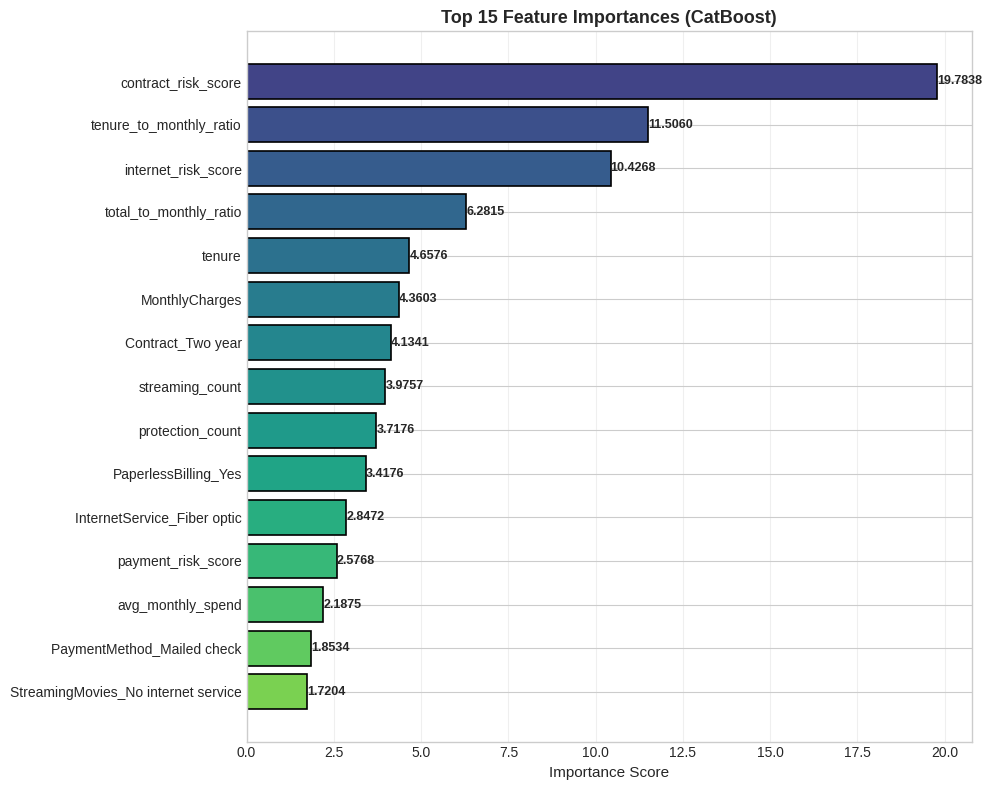

ENGINEERED FEATURE CONTRIBUTION

Engineered features in top 20: 9

Engineered feature rankings:
  #1: contract_risk_score (importance=19.7838)
  #2: tenure_to_monthly_ratio (importance=11.5060)
  #3: internet_risk_score (importance=10.4268)
  #4: total_to_monthly_ratio (importance=6.2815)
  #8: streaming_count (importance=3.9757)
  #9: protection_count (importance=3.7176)
  #12: payment_risk_score (importance=2.5768)
  #13: avg_monthly_spend (importance=2.1875)
  #16: service_count (importance=1.7115)


In [37]:
# Plot top 15 features
plt.figure(figsize=(10, 8))
top_n = 15
top_features = importance_df.head(top_n)
colors = plt.cm.viridis(np.linspace(0.2, 0.8, top_n))
bars = plt.barh(range(top_n), top_features['Importance'].values, 
                color=colors, edgecolor='black', linewidth=1.2)
plt.yticks(range(top_n), top_features['Feature'].values, fontsize=10)
plt.xlabel('Importance Score', fontsize=11)
plt.title(f'Top {top_n} Feature Importances ({best_model_name})', fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()

# Add value labels
for bar, val in zip(bars, top_features['Importance'].values):
    plt.text(val + 0.005, bar.get_y() + bar.get_height()/2, 
             f'{val:.4f}', va='center', fontsize=9, fontweight='bold')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# Check engineered feature contribution
print("ENGINEERED FEATURE CONTRIBUTION")
engineered_feats = ['tenure_to_monthly_ratio', 'total_to_monthly_ratio', 'service_count',
                    'contract_risk_score', 'payment_risk_score', 'avg_monthly_spend',
                    'internet_risk_score', 'streaming_count', 'protection_count']
engineered_importance = importance_df[importance_df['Feature'].isin(engineered_feats)]
print(f"\nEngineered features in top 20: {len(engineered_importance)}")

if len(engineered_importance) > 0:
    print("\nEngineered feature rankings:")
    for idx, row in engineered_importance.iterrows():
        print(f"  #{idx+1}: {row['Feature']} (importance={row['Importance']:.4f})")

## Step 5.1: Save Model Artifacts for Deployment

**Purpose:** Save the trained model, preprocessor, and feature names for use in the Streamlit app.

**What we save:**
1. `best_churn_model.pkl` — Trained best model (XGBoost/LightGBM/CatBoost)
2. `preprocessor.pkl` — Fitted ColumnTransformer (scaling, encoding)
3. `feature_names.pkl` — Feature names for consistent column ordering

**Why save separately?**
- Streamlit app loads these files at runtime
- Keeps app code clean and focused on UI logic
- Enables model updates without changing app code

In [38]:
import joblib

# Save model artifacts
joblib.dump(best_model, 'best_churn_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')
joblib.dump(all_feature_names, 'feature_names.pkl')

print("MODEL ARTIFACTS SAVED")
print(" best_churn_model.pkl")
print(" preprocessor.pkl")
print(" feature_names.pkl")

MODEL ARTIFACTS SAVED
 best_churn_model.pkl
 preprocessor.pkl
 feature_names.pkl


## Step 5.2: Streamlit App Code

**Purpose:** Create a standalone Python script for the interactive churn prediction UI.

**Features:**
- Clean sidebar form for customer input
- Real-time prediction with probability score
- Risk level indicator (Low/Medium/High)
- Top risk factors display
- Retention recommendations

**How to run:**
1. Save code as `churn_prediction_app.py`
2. Install Streamlit: `pip install streamlit`
3. Run: `streamlit run churn_prediction_app.py`
4. Access at: http://localhost:8501

**Deployment:**
- Push to GitHub
- Connect to Streamlit Cloud (free hosting)
- App is live in minutes

## Step 5.3: Save All Results to CSV

**Purpose:** Export model comparison results, cross-validation scores, and feature importance for documentation.

**Files created:**
1. `model_comparison_results.csv` — ROC-AUC, F1, Precision, Recall for all models
2. `cross_validation_results.csv` — 5-fold CV scores with mean ± std
3. `feature_importance.csv` — All features ranked by importance

**Why save?**
- Portfolio documentation — show quantitative results
- Easy to create tables in README.md
- Reproducibility — others can verify your results

In [39]:
import pandas as pd

# Create results_df
if 'results_df' not in globals():
    results = []
    for name, model in [('XGBoost', xgb_model), ('LightGBM', lgb_model), ('CatBoost', cb_model)]:
        y_pred_proba = model.predict_proba(X_test_processed)[:, 1]
        y_pred = model.predict(X_test_processed)
        
        results.append({
            'Model': name,
            'ROC-AUC': round(roc_auc_score(y_test, y_pred_proba), 4),
            'F1-Score': round(f1_score(y_test, y_pred), 4),
            'Precision': round(precision_score(y_test, y_pred), 4),
            'Recall': round(recall_score(y_test, y_pred), 4)
        })
    results_df = pd.DataFrame(results)

if 'cv_results_df' not in globals():
    cv_results_df = pd.DataFrame([{
        'Model': 'XGBoost',
        'CV ROC-AUC Mean': round(cv_scores.mean(), 4),
        'CV ROC-AUC Std': round(cv_scores.std(), 4),
        'CV ROC-AUC Min': round(cv_scores.min(), 4),
        'CV ROC-AUC Max': round(cv_scores.max(), 4)
    }])

if 'importance_df' not in globals():
    importance = xgb_model.feature_importances_
    importance_df = pd.DataFrame({
        'Feature': all_feature_names,
        'Importance': importance
    }).sort_values('Importance', ascending=False).reset_index(drop=True)

results_df.to_csv('model_comparison_results.csv', index=False)
cv_results_df.to_csv('cross_validation_results.csv', index=False)
importance_df.to_csv('feature_importance.csv', index=False)

print("RESULTS EXPORTED")
print(" model_comparison_results.csv")
print(" cross_validation_results.csv")
print(" feature_importance.csv")

RESULTS EXPORTED
 model_comparison_results.csv
 cross_validation_results.csv
 feature_importance.csv
